In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const

from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
data, var = load_data_and_var()

In [3]:
nfws_full=generate_nfws_from_combined_dataset_werr(data, var)

In [4]:
nfws = [nfw for nfw in nfws_full if nfw.z < 0.2]

In [5]:
nfws_subset = [nfw for nfw in nfws if nfw.energies.is_virialized_gaspari ]
zs = [nfw.z for nfw in nfws_subset]
filtered_vir = [nfw.energies.virialization_fraction_gaspari for nfw in nfws_subset]

len(nfws_subset)

94

In [11]:
masses = [n.M500.value/1e14 for n in nfws_subset]
luminosities = [n.L500.value for n in nfws_subset]

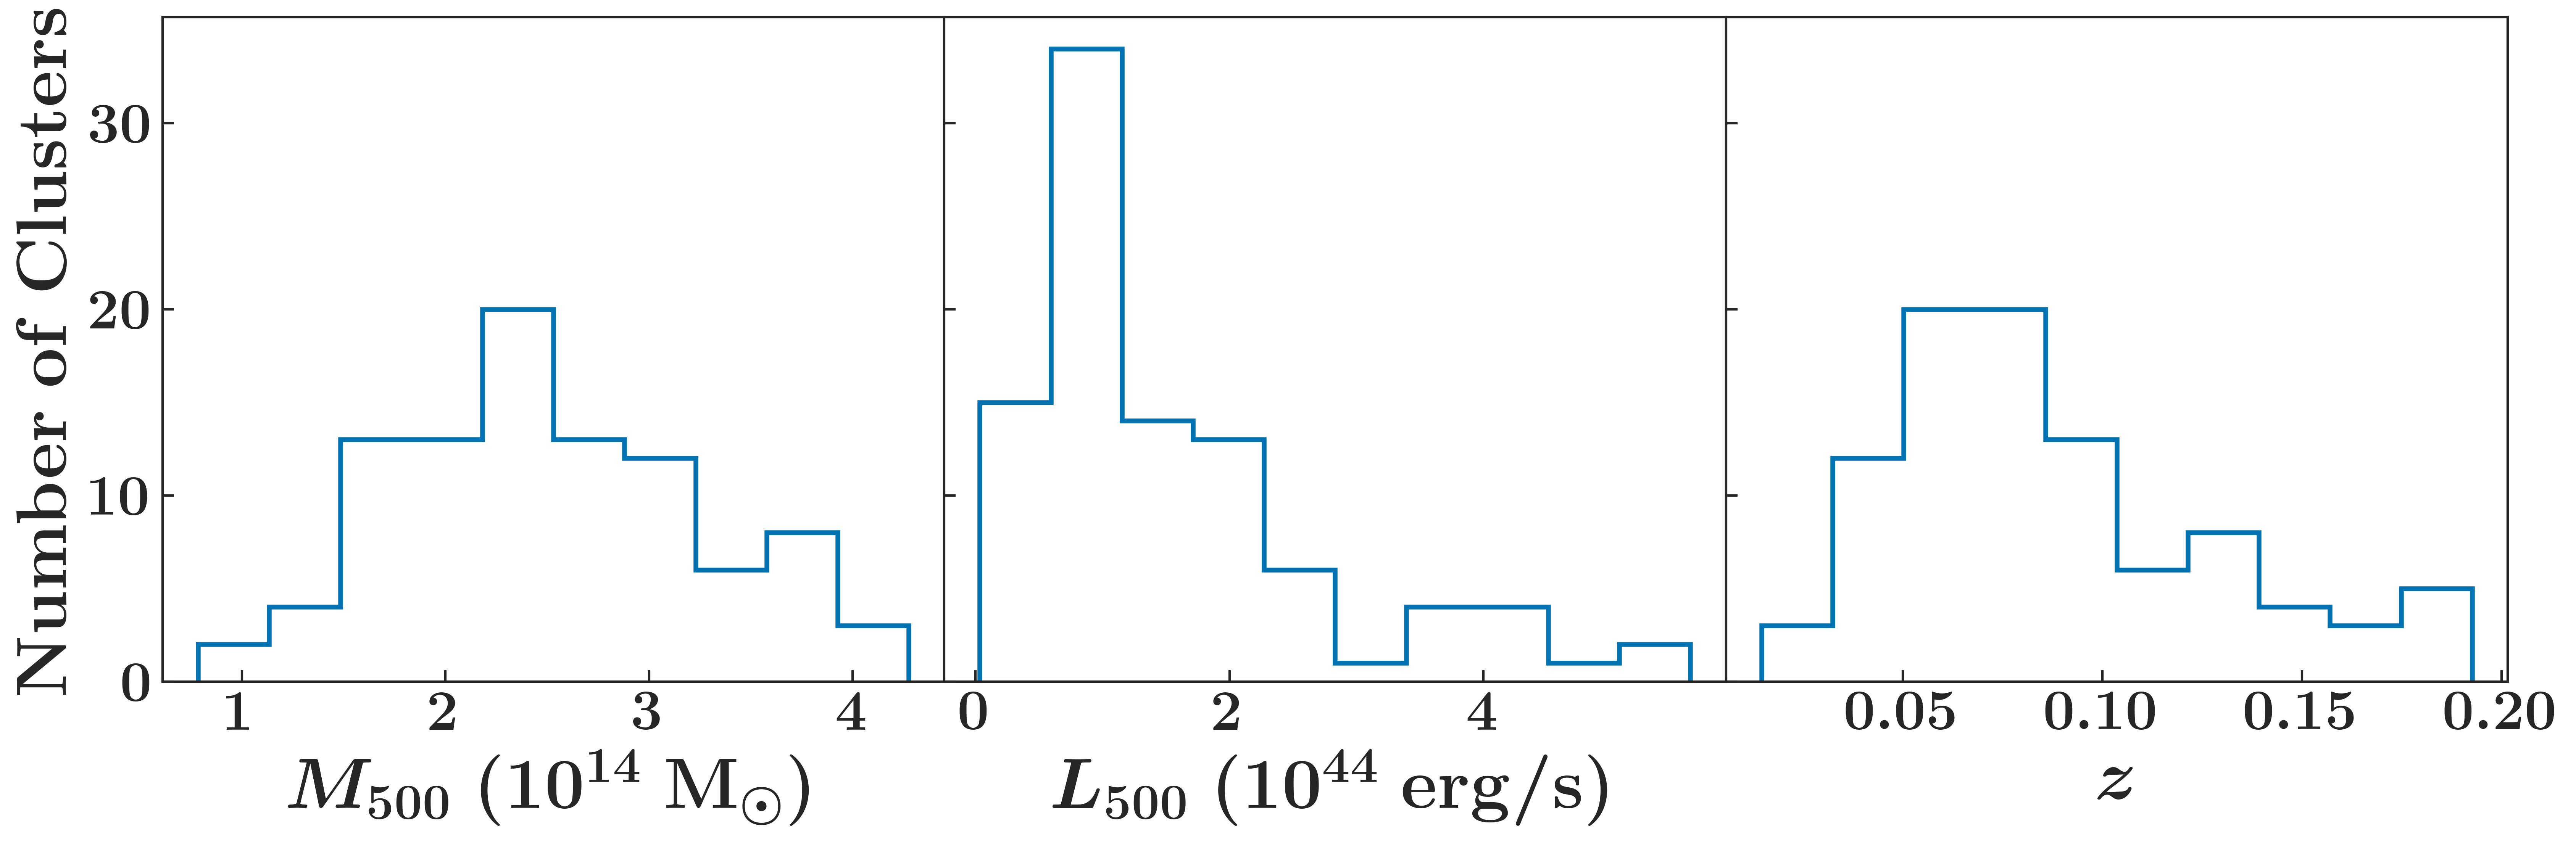

<Figure size 600x400 with 0 Axes>

In [12]:
paper_plot()
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, gridspec_kw={'wspace': 0}, dpi=450)  # 1 row, 3 columns

# First subplot
axes[0].hist(masses, histtype='step', lw=2)
axes[0].set_xlabel(f'$M_{{500}} ~ (10^{{14}} ~\\mathrm{{M_{{\\odot}}}})$', size=30)
axes[0].set_ylabel(f'$\\mathrm{{Number~of~Clusters}}$', size=30)

# Second subplot
axes[1].hist(luminosities, histtype='step', lw=2)
axes[1].set_xlabel(f'$L_{{500}}~ (10^{{44}} ~ \\mathrm{{erg/s}})$', size=30)
#axes[1].set_ylabel(f'$\\mathrm{{Number~of~Clusters}}$')

# Third subplot
axes[2].hist(zs, histtype='step', lw=2)
axes[2].set_xlabel(f'$z$', size=30)
#axes[2].set_ylabel(f'$\\mathrm{{Number~of~Clusters}}$')


[ax.tick_params(axis='both', labelsize='24', direction='in') for ax in axes]
plt.tight_layout()  # Adjusts the layout so the labels and titles fit within the figure
plt.show()
    
#fig.savefig('plots/REFLEX_clusters.pdf', bbox_inches='tight')
plt.tight_layout()

In [14]:
savefig(fig,'plots/cluster_properties.png') 

2024-07-25T09:51:20.909206: made plots/cluster_properties.png


In [15]:
np.min(masses), np.max(masses)

(0.7850759999999999, 4.275729999999999)

In [16]:
np.min(luminosities), np.max(luminosities)

(0.034601, 5.629624)

In [17]:
np.min(zs), np.max(zs)

(0.0146, 0.1926)

In [18]:
(1e37*u.W).to(1e44*u.erg/u.s)

<Quantity 1. 1e+44 erg / s>